# Kaj o tem pravijo drugi? Naše ugotovitve ob objavljenih študijah
### Primerjava z obstoječimi raziskavami

V prvem zvezku (*Zgodba v grafih*) smo pokazali, kdaj in zakaj so tehnološka podjetja po letu 2020 napovedovala odpuščanja, katera podjetja in kako se je odzvala borza. Tu preverimo, ali drugi raziskovalci, ki so delali z **drugimi podatki**, pridejo do istih sklepov. Nobena od uporabljenih študij ne temelji na seznamu Layoffs.fyi, ki ga uporabljamo mi, zato je vsaka neodvisna preverba.

Kjer je bilo mogoče, nismo le primerjali številk, ampak smo **ponovili metodo študije na naših podatkih**, da je primerjava poštena.

**Kako brati:** najprej je tabela z vsemi primerjavami in oceno (*se ujema*, *delno*, *se razlikuje*, *ni primerljivo*). Ocena ni naše mnenje, ampak jo izračuna pravilo iz številk (na primer: ali interval negotovosti vključuje ničlo). Nato sledi graf za vsako primerjavo s štirimi kratkimi razlagami: **Kaj vidimo?**, **Zakaj smo to naredili?**, **Kaj to pomeni?** in **Česa ne vemo?**, ter vrstica **Viri podatkov** z izvornimi viri in točnimi datotekami.

In [1]:
from pathlib import Path
import os, sys
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)          # poti do podatkov so relativne glede na mapo projekta
import plotly.io as pio
from analysis import compare_viz as cv
from analysis.viz_theme import explanation_markdown
from analysis.data_sources import sources_markdown

# Grafi se vidijo v JupyterLab in v izvoženem HTML (ta potrebuje internet, da naloži plotly.js).
# Za izvoz, ki dela brez interneta, zamenjaj z "notebook".
pio.renderers.default = "plotly_mimetype+notebook_connected"

data = cv.prepare_compare_data()                       # zažene primerjave na lokalnih podatkih (okoli minuta)
items = cv.build_comparisons_a(data)                   # ime -> (graf, razlage, vrstica tabele)
try:                                                   # primerjave za objave in zemljevid pripravi drugi del ekipe
    from analysis import compare_text_geo as ctg
    items.update(ctg.build_comparisons_b())
except Exception:
    pass
verdicts = cv.verdicts_earlier(data.get("stock_summary"), data["weekly"], data["h2"]) + [v for _, _, v in items.values()]


def show(name):
    """Graf, pod njim štiri razlage v preprostem jeziku in vrstica z viri podatkov."""
    fig, parts, _ = items[name]
    fig.show()
    display(Markdown(explanation_markdown(parts) + "\n\n" + sources_markdown(name)))


def show_group(prefix, missing_text):
    names = sorted(n for n in items if n.startswith(prefix))
    if not names:
        display(Markdown(missing_text))
    for n in names:
        show(n)

## Povzetek: naše ugotovitve ob objavljenih študijah

Prve tri vrstice so ugotovitve iz prvega zvezka (številke so izračunane znova); ostale so nove primerjave v tem zvezku.

In [2]:
display(Markdown(cv.verdict_markdown(verdicts)))

| Tema | Študija | Njihov rezultat | Naš rezultat | Ocena |
|---|---|---|---|---|
| Odziv borze na napoved odpuščanj | Farber in Hallock (2009); Floros in sod. (2023); Eshghi in Astvansh (2024) | negativen, a vse šibkejši skozi desetletja; leta 2020 brez učinka | -0,58 % v dneh 0 in +1 (interval od -1,29 % do +0,13 %) | **se ujema** |
| Kdaj se je začel val | Bailey in Hernandez Martinez (2023, Cleveland Fed); Bernard (2025, Indeed) | dražje zadolževanje je zmanjšalo prosta mesta; skoraj polovica padca oglasov pred ChatGPT | napovedi na teden: ob zvišanju obrestne mere 1,0 → 15,4, ob ChatGPT 21,3 → 21,6 | **se ujema** |
| Uradna stopnja odpuščanj | Cohen (2023, Kansas City Fed) | kljub zvišanju obrestnih mer se stopnja odpuščanj skoraj ni spremenila | informacijski sektor (JOLTS): 1,17 % → 1,15 % na mesec | **se ujema** |
| Koliko ljudi | Challenger, Gray & Christmas (mesečna poročila) | 2022: 97.171 / 2023: 168.032 / 2024: 133.988 / 2025: 154.445 | 2022: 108.546 / 2023: 178.725 / 2024: 106.727 / 2025: 102.756 | **se ujema** |
| Borza in velikost odpuščanja | Worrell in sod. (1991); Eshghi in Astvansh (2024) | večja odpuščanja borza kaznuje bolj | nad 10 % zaposlenih -1,91 %, do 10 % -0,51 %; razlika od -3,87 % do +1,32 % | **delno** |
| Padec prihodkov in odpuščanja | Weingarden (2017), Federal Reserve FEDS 2017-088 | padec prihodkov poveča verjetnost odpuščanja znotraj podjetja | -0,02 odstotne točke (interval -1,01 do 0,98) | **se razlikuje** |
| Preveliko zaposlovanje v pandemiji | Srivastava, Govindarajan, Rajgopal in Tanone (2023) | odpuščala so podjetja, ki so v pandemiji najbolj zaposlovala; odpuščanja so bila majhna glede na prejšnjo rast | napovedi odpuščanj: 8 % → 27 % po četrtinah rasti (ob upoštevanju velikosti obeti 1,34-krat, interval 0,93 do 2,22); krčenje zaposlenih 2022-2023 ni povezana z rastjo (korelacija 0,02); 55 % podjetij, ki so krčila, je še nad ravnjo 2019 | **delno** |

## 1. Koliko ljudi? Naš seznam ob neodvisnem štetju

Naše številke odpuščenih ljudi prihajajo iz zbirke novic. Ali neodvisno štetje (Challenger, Gray & Christmas, na katerem temelji tudi študija Federal Reserve) pokaže podobno sliko?

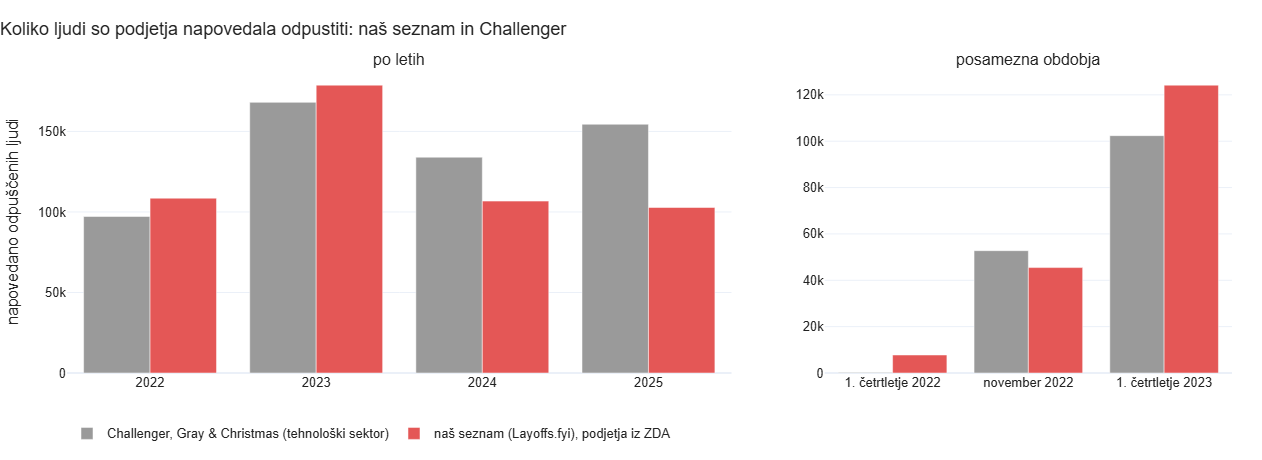

**Kaj vidimo?** Sivi stolpci so podatki podjetja Challenger, Gray & Christmas, ki že od leta 1993 šteje napovedana odpuščanja ameriških podjetij po panogah; tu je njihov tehnološki sektor. Rdeči stolpci so seštevek ljudi iz našega seznama, le za podjetja s sedežem v ZDA. Levo so cela leta, desno tri krajša obdobja, ki jih Challenger objavlja posebej. Z miško vidite, kolikšen del naših napovedi sploh navede število ljudi.

**Zakaj smo to naredili?** Naš seznam (Layoffs.fyi) je zbirka novic, ki jo ureja ena oseba. Preveriti smo želeli, ali neodvisno štetje pride do podobnih številk, preden se na naše številke zanesemo.

**Kaj to pomeni?** Obe štetji imata vrh v istem letu. V letih 2022, 2023 sta števili blizu (razlika do četrtine). Po letih (naš seznam proti Challengerju): 2022: 108.546 proti 97.171, 2023: 178.725 proti 168.032, 2024: 106.727 proti 133.988, 2025: 102.756 proti 154.445. Velika izjema je prvo četrtletje 2022: pri nas 7.762 ljudi, pri Challengerju le 267, kar kaže, da Challenger v tehnološki sektor šteje ožji krog podjetij kot naš seznam. Dva neodvisna vira torej kažeta isti val odpuščanj; naše številke niso izmišljene, so pa le približne.

**Česa ne vemo?** Naše številke so spodnja meja: le približno 63 % napovedi pove, koliko ljudi bodo odpustili. Oba vira štejeta napovedi, ne dejansko izgubljenih služb, in »tehnologijo« opredelita različno (naš seznam ima tudi finančna, prodajna in prevozna tehnološka podjetja). Challengerjeve številke smo prepisali iz njihovih mesečnih poročil.

**Viri podatkov:** Layoffs.fyi, javni seznam napovedi odpuščanj v tehnoloških podjetjih (ročno prenesen): `data/processed/layoffs_clean.csv`.

In [3]:
if "9a_challenger" in items:
    show("9a_challenger")

## 2. Ali borza bolj kaznuje večja odpuščanja?

V prvem zvezku je bil povprečni odziv borze majhen. Študije pravijo, da je odziv odvisen od tega, kako veliko je odpuščanje. Isto analizo smo ponovili in objave razdelili po deležu odpuščenih zaposlenih.

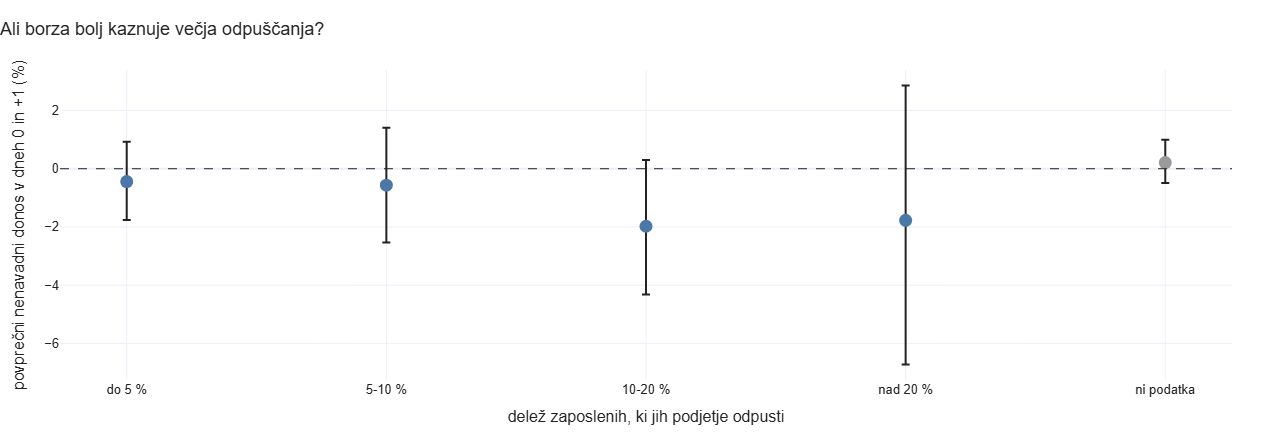

**Kaj vidimo?** Vsaka pika je povprečni »nenavadni donos« delnice v dnevu objave in naslednjem dnevu, to je sprememba cene, ki je ne pojasni gibanje celotne borze. Objave smo razdelili po tem, kolikšen del zaposlenih podjetje odpusti. Navpične črte kažejo 95-odstotni interval negotovosti; siva pika so objave, ki deleža ne navedejo.

**Zakaj smo to naredili?** Starejše raziskave (Worrell, Davidson in Sharma 1991) in pregled 78 študij (Eshghi in Astvansh 2024) ugotavljajo, da borza večja odpuščanja kaznuje bolj. Preverili smo, ali to velja tudi za tehnološka podjetja po letu 2020.

**Kaj to pomeni?** Pri odpuščanjih več kot desetine zaposlenih je povprečni odziv -1,91 % (152 objav), pri manjših -0,51 % (226 objav). Odziv pri večjih je torej bolj negativen: razlika -1,40 %, interval od -3,87 % do +1,32 %. Interval vključuje ničlo, zato razlika lahko nastane tudi po naključju: smer je ista kot v študijah, dokaza pa nimamo. Objave brez navedenega deleža imajo povprečje +0,21 %; zato je bil skupni odziv vseh objav tako majhen.

**Česa ne vemo?** Delež navede le 378 od 611 objav, in to morda ne naključno izbranih. Večja odpuščanja so pogosto v podjetjih, ki jim že sicer slabo gre, zato velikost odpuščanja in slabe novice o poslovanju težko ločimo. Starejše študije merijo drugače (pogosto število ljudi, ne delež) in v drugih desetletjih.

**Viri podatkov:** Layoffs.fyi, javni seznam napovedi odpuščanj v tehnoloških podjetjih (ročno prenesen): `data/processed/layoffs_clean.csv`; SEC EDGAR, javna finančna poročila ameriških borznih podjetij: `data/raw/sec_company_matches.csv`; Yahoo Finance, dnevne cene delnic (prenesene s knjižnico yfinance): `data/raw/prices_daily.csv`. Graf bere obdelano datoteko `data/processed/event_study_events.csv` (izdela jo `python -m analysis.event_study`).

In [4]:
show_group("9a_borza", "*Ta del bo na voljo, ko bodo prenesene cene delnic in narejena analiza borze (python -m analysis.event_study).*")

## 3. Ali padec prihodkov napove odpuščanje znotraj podjetja?

V prvem zvezku je napoved odpuščanj najbolj napovedala velikost podjetja. Študija Federal Reserve namesto tega primerja vsako podjetje samo s seboj. Naredili smo enako.

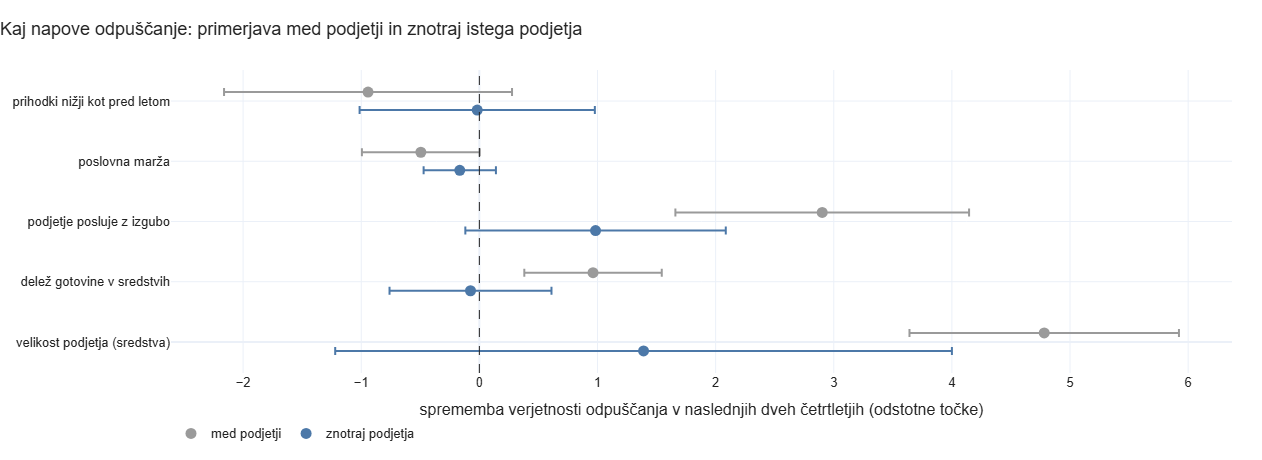

**Kaj vidimo?** Vsaka pika pove, za koliko odstotnih točk se spremeni verjetnost, da podjetje v naslednjih dveh četrtletjih napove odpuščanja, če se ena lastnost spremeni (pri lastnostih z da/ne: razlika med »da« in »ne«; pri drugih: sprememba za en standardni odklon). Sive pike primerjajo podjetja med seboj, modre vsako podjetje samo s seboj v drugih četrtletjih. Črte so 95-odstotni intervali.

**Zakaj smo to naredili?** Študija Federal Reserve (Weingarden 2017) je pokazala, da podjetje odpušča, ko mu prihodki padajo, in to znotraj istega podjetja. Naš model je prej primerjal podjetja med seboj, in tam je vse preglasila velikost. Zato smo uporabili njihov pristop.

**Kaj to pomeni?** Ko podjetje primerjamo samo s seboj, nižji prihodki kot pred letom spremenijo verjetnost za -0,02 točke (interval -1,01 do 0,98), pri osnovni verjetnosti okoli 5 %. Padec prihodkov torej ne napove odpuščanja niti znotraj podjetja; tu se z ameriško študijo ne ujemamo. Velikost podjetja med podjetji poveča verjetnost za 4,8 točke na standardni odklon, znotraj podjetja pa učinka ni več, ker se velikost v nekaj letih skoraj ne spremeni. Odpuščanj tehnoloških podjetij po letu 2020 torej ne moremo pojasniti s padcem prihodkov; razlog moramo iskati drugje (na primer v prejšnjem zaposlovanju, glej naslednji graf).

**Česa ne vemo?** Primerjava podjetja s samim seboj deluje le pri podjetjih, ki imajo četrtletja z odpuščanji in brez njih; takih je 163 od 824, zato so intervali široki. Študija je opazovala obdobje 2007-2012 z veliko recesijo, ko so prihodki res padali, mi pa obdobje, ko so prihodki večine tehnoloških podjetij še rasli. Model je linearen in pokaže povezave, ne vzrokov.

**Viri podatkov:** SEC EDGAR, javna finančna poročila ameriških borznih podjetij: `data/raw/sec_financials_quarterly.csv`, `data/raw/sec_revenue_universe.csv`, `data/raw/sec_universe_sic.csv`, `data/raw/sec_company_matches.csv`; Layoffs.fyi, javni seznam napovedi odpuščanj v tehnoloških podjetjih (ročno prenesen): `data/processed/layoffs_clean.csv`. Graf bere obdelano datoteko `data/processed/company_panel.csv` (izdela jo `python -m analysis.company_panel`).

In [5]:
show("9a_znotraj")

## 4. Ali so odpuščala podjetja, ki so prej preveč zaposlovala?

Za to primerjavo smo zbrali nove podatke: število zaposlenih iz letnih poročil (10-K), ki jih ameriška podjetja oddajo nadzorniku borze SEC.

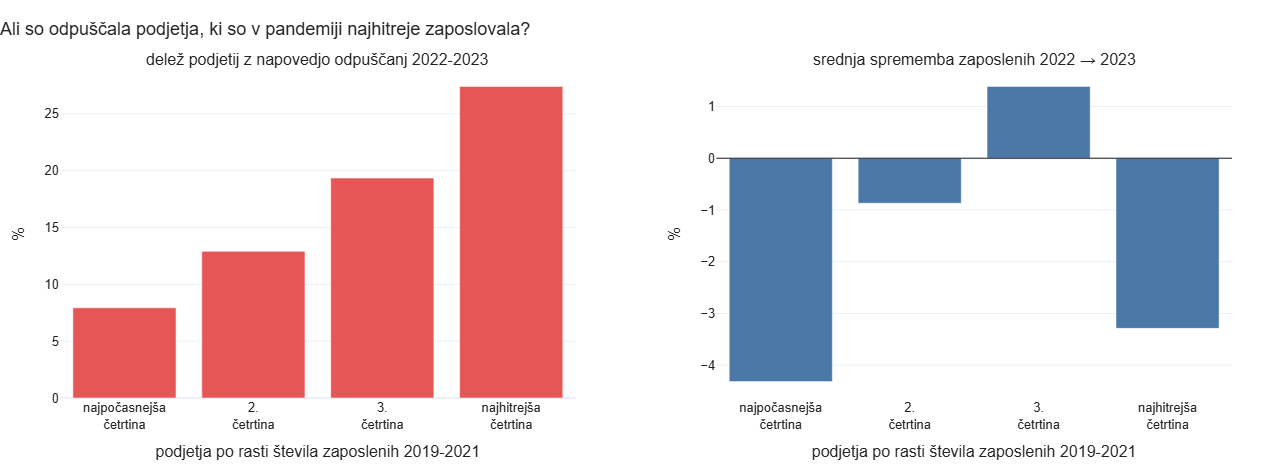

**Kaj vidimo?** Podjetja smo razdelili v četrtine po tem, za koliko se je med letoma 2019 in 2021 povečalo število zaposlenih (iz letnih poročil 10-K). Levo je delež podjetij v vsaki četrtini, ki so v letih 2022-2023 napovedala odpuščanja. Desno je srednja sprememba števila zaposlenih od konca 2022 do konca 2023 v istih četrtinah, kar ni odvisno od našega seznama napovedi.

**Zakaj smo to naredili?** Najpogostejša razlaga (na primer Srivastava in sod. 2023) je, da so podjetja v pandemiji zaposlila preveč in so odpuščanja popravek. Prej tega nismo mogli preveriti, ker nismo imeli števila zaposlenih; zdaj ga imamo za 249 tehnoloških podjetij.

**Kaj to pomeni?** Delež podjetij z napovedjo odpuščanj raste od 8 % v najpočasnejši do 27 % v najhitrejši četrtini; tudi ob upoštevanju velikosti podjetja so obeti 1,34-krat večji na standardni odklon rasti (interval 0,93 do 2,22). Povezava ni dovolj zanesljiva, da bi razlago o prevelikem zaposlovanju potrdili. Pri dejanskem številu zaposlenih pa kasnejše krčenje ni povezano s prejšnjo hitrostjo zaposlovanja (korelacija 0,02, interval -0,13 do 0,17). Podjetja, ki so zaposlene zmanjšala, so jih v srednjem za 8,5 %, po prej +13,7 % rasti; 55 % jih je imelo leta 2023 še vedno več zaposlenih kot leta 2019. Tudi Srivastava in sod. ugotavljajo, da so bila odpuščanja majhna v primerjavi s prejšnjim zaposlovanjem.

**Česa ne vemo?** Število zaposlenih smo prebrali iz besedila letnih poročil s pravili za iskanje stavkov; ročni pregled vzorca je pokazal, da je okoli 9 od 10 števil pravilnih. Podjetja štejejo različno (nekatera vključijo pogodbene sodelavce), število pa velja za en dan v letu, zato odpuščanja in nova zaposlovanja v istem letu ne vidimo ločeno. Leva slika temelji na našem seznamu napovedi, ki ne zajame vseh odpuščanj.

**Viri podatkov:** SEC EDGAR, letna poročila 10-K (število zaposlenih, prebrano iz besedila): `data/raw/sec_headcount.csv`; SEC EDGAR, javna finančna poročila ameriških borznih podjetij: `data/raw/sec_financials_quarterly.csv`, `data/raw/sec_revenue_universe.csv`, `data/raw/sec_universe_sic.csv`, `data/raw/sec_company_matches.csv`; Layoffs.fyi, javni seznam napovedi odpuščanj v tehnoloških podjetjih (ročno prenesen): `data/processed/layoffs_clean.csv`.

In [6]:
show_group("9a_zaposlovanje", "*Ta del bo na voljo, ko bo preneseno število zaposlenih (python collect.py --sources sec_headcount).*")

## 5. Objave za delo in kje se zaposluje

Primerjave za delo na daljavo, umetno inteligenco, mlade delavce in regije (podatki Hacker News in zemljevid) pripravi drugi del ekipe.

In [7]:
show_group("9b_", "*Ta del bomo dodali, ko bo pripravljen.*")

*Ta del bomo dodali, ko bo pripravljen.*

## Česa ta primerjava ne pove

- **Študije merijo drugače.** Nekatere štejejo oglase za delo, druge dejanske zaposlene ali napovedi; nekatere opazujejo druga desetletja ali vse panoge. Kjer se razlikujemo, je razlog pogosto v tem in ne v napaki.
- **Ujemanje ni dokaz vzroka.** Če dva vira pokažeta isto povezavo, je ta bolj verjetno resnična, ne pa nujno vzročna.
- **Ocene so groba pravila.** »Delno« pomeni, da se ujema smer, ne pa tudi zanesljivost ali velikost.
- **Objavljene številke smo prepisali.** Številke študij smo prepisali iz člankov in poročil (povezave spodaj); niso v naših datotekah.

## Viri

**Recenzirani članki**
- Acemoglu, D., Autor, D., Hazell, J. in Restrepo, P. (2022). [Artificial Intelligence and Jobs: Evidence from Online Vacancies](https://doi.org/10.1086/718327). *Journal of Labor Economics* 40(S1), S293-S340.
- Eshghi, K. in Astvansh, V. (2024). [Stock investors' reaction to layoff announcements: A meta-analysis](https://doi.org/10.1111/1748-8583.12532). *Human Resource Management Journal*.
- Farber, H. S. in Hallock, K. F. (2009). [The changing relationship between job loss announcements and stock prices: 1970-1999](https://econpapers.repec.org/RePEc:eee:labeco:v:16:y:2009:i:1:p:1-11). *Labour Economics* 16(1), 1-11.
- Floros, C., Psillaki, M. in Karpouzis, E. (2023). [Layoffs and stock market performance during the COVID-19 pandemic: evidence from the US](https://doi.org/10.1108/JES-05-2021-0224). *Journal of Economic Studies* 50(2), 96-108.
- Worrell, D. L., Davidson, W. N. in Sharma, V. M. (1991). [Layoff announcements and stockholder wealth](https://doi.org/10.2307/256410). *Academy of Management Journal* 34(3), 662-678.

**Delovni članki in raziskave centralnih bank**
- Bailey, A. in Hernandez Martinez, V. (2023). [The Effect of Higher Financing Costs on Job Openings and Online Job Postings](https://doi.org/10.26509/frbc-ec-202309). Federal Reserve Bank of Cleveland, Economic Commentary 2023-09.
- Brynjolfsson, E., Chandar, B. in Chen, R. (2025). [Canaries in the Coal Mine?](https://digitaleconomy.stanford.edu/publications/canaries-in-the-coal-mine/) Stanford Digital Economy Lab.
- Cohen, E. (2023). [Post-Pandemic Labor Shortages Have Limited the Effect of Monetary Policy on the Labor Market](https://www.kansascityfed.org/research/economic-bulletin/post-pandemic-labor-shortages-have-limited-the-effect-of-monetary-policy-on-the-labor-market/). Federal Reserve Bank of Kansas City.
- Hansen, S. in sod. (2026). [Remote Work Across Jobs, Companies and Space](https://doi.org/10.24149/wp2629). Federal Reserve Bank of Dallas, Working Paper 2629.
- Weingarden, A. (2017). [The Timing of Mass Layoff Episodes: Evidence from U.S. Microdata](https://doi.org/10.17016/FEDS.2017.088). Federal Reserve Board, FEDS 2017-088.

**Poročila**
- Bernard, B. (2025). [The US Tech Hiring Freeze Continues](https://hiringlab.indeed.com/2025/07/30/the-us-tech-hiring-freeze-continues/). Indeed Hiring Lab.
- Challenger, Gray & Christmas: mesečna poročila o napovedanih odpuščanjih ([december 2023](https://www.challengergray.com/?p=20395), [december 2024](https://www.challengergray.com/?p=24257), [konec 2025](https://www.challengergray.com/?p=27592), [februar 2023](https://www.challengergray.com/?p=17169), [marec 2023](https://www.challengergray.com/?p=17832)).
- Muro, M. in You, Y. (2022). [Superstars, rising stars, and the rest](https://www.brookings.edu/articles/superstars-rising-stars-and-the-rest-pandemic-trends-and-shifts-in-the-geography-of-tech/). Brookings Metro.
- Srivastava, A., Govindarajan, V., Rajgopal, S. in Tanone, J. (2023). [Are Tech Layoffs a Major Disruption or a Just Minor Course Correction from Past Excesses?](https://cmr.berkeley.edu/2023/03/are-tech-layoffs-a-major-disruption-or-a-just-minor-course-correction-from-past-excesses/) California Management Review Insight.